**Импорт необходимых библиотек и подготовка данных**

In [1]:
# импорт
import json
import pandas as pd
import numpy as np
from pandas import json_normalize

print(np.__version__)

1.26.4


In [2]:
# импорт файла resort_open_data, который ранее был собран парсером collect_resort_open_data.py
with open ('resort_open_data.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

print(data)

{'collectedAt': '2026-09-14T12:13:58.823Z', 'resorts': [{'resort_id': 'R001', 'name_ru': 'Роза Хутор', 'region': 'Краснодарский край', 'wiki_query': 'Роза Хутор горнолыжный курорт', 'fallback_lat': 43.67097, 'fallback_lon': 40.29708, 'latitude': 43.64639, 'longitude': 40.33222, 'coordinate_source': 'Wikipedia', 'coordinate_source_title': 'Роза Хутор', 'coordinate_source_url': 'https://ru.wikipedia.org/wiki/%D0%A0%D0%BE%D0%B7%D0%B0_%D0%A5%D1%83%D1%82%D0%BE%D1%80', 'wikidata_id': 'Q1335490', 'coordinate_quality': 'nearby_feature_proxy', 'coordinate_distance_from_seed_km': 3.9, 'piste_segments_6km': 334, 'lift_lines_6km': 64, 'lodging_objects_6km': 86, 'food_objects_6km': 107, 'transport_objects_6km': 45, 'attraction_objects_6km': 42, 'osm_data_timestamp': '2026-09-14T12:12:58Z', 'osm_radius_km': 6, 'osm_overlap_warning': 'Possible overlap with Газпром Поляна (6.0 km), Красная Поляна (7.3 km)', 'open_meteo_elevation_m': 950, 'open_meteo_timezone': 'Europe/Moscow', 'winter_mean_temperature

In [3]:
resorts_list = data['resorts']
resort_open_data_df = json_normalize( resorts_list, sep="_", max_level=1 )

In [4]:
list(resort_open_data_df.columns)

['resort_id',
 'name_ru',
 'region',
 'wiki_query',
 'fallback_lat',
 'fallback_lon',
 'latitude',
 'longitude',
 'coordinate_source',
 'coordinate_source_title',
 'coordinate_source_url',
 'wikidata_id',
 'coordinate_quality',
 'coordinate_distance_from_seed_km',
 'piste_segments_6km',
 'lift_lines_6km',
 'lodging_objects_6km',
 'food_objects_6km',
 'transport_objects_6km',
 'attraction_objects_6km',
 'osm_data_timestamp',
 'osm_radius_km',
 'osm_overlap_warning',
 'open_meteo_elevation_m',
 'open_meteo_timezone',
 'winter_mean_temperature_c',
 'avg_snowfall_cm_per_season',
 'avg_freezing_days_per_season',
 'avg_snow_days_per_season',
 'max_daily_snowfall_cm',
 'weather_period_start',
 'weather_period_end',
 'nearest_scheduled_airport',
 'nearest_airport_iata',
 'nearest_airport_distance_km',
 'nearest_airport_municipality',
 'completeness_pct',
 'quality_flags',
 'collected_at',
 'weather_model',
 'coordinate_error']

In [5]:
def make_df_from_json(json_file_link):
  with open (json_file_link, 'r', encoding='utf-8') as f:
    new_file = json.load(f)

  new_df = pd.DataFrame(new_file)

  new_df.columns = new_df.iloc[0]
  new_df = new_df.drop(0).reset_index(drop=True)

  return new_df

In [6]:
# импорт файлов climate_monthly, prices_monthly, resorts
climate_df = make_df_from_json('climate_monthly.json')
prices_df = make_df_from_json('prices_monthly.json')
resorts_df = make_df_from_json('resorts.json')

In [7]:
list(climate_df.columns)

['resort_id',
 'name_ru',
 'region',
 'month',
 'month_name_ru',
 'years_count',
 'mean_temperature_c',
 'avg_monthly_precipitation_mm',
 'avg_monthly_snowfall_cm',
 'avg_freezing_days',
 'avg_snow_days',
 'weather_model']

In [8]:
list(resorts_df.columns)

['resort_id',
 'name_ru',
 'region',
 'latitude',
 'longitude',
 'coordinate_quality',
 'coordinate_source_title',
 'coordinate_source_url',
 'wikidata_id',
 'piste_segments_6km',
 'lift_lines_6km',
 'lodging_objects_6km',
 'food_objects_6km',
 'transport_objects_6km',
 'attraction_objects_6km',
 'osm_radius_km',
 'osm_overlap_warning',
 'open_meteo_elevation_m',
 'winter_mean_temperature_c',
 'avg_snowfall_cm_per_season',
 'avg_freezing_days_per_season',
 'avg_snow_days_per_season',
 'max_daily_snowfall_cm',
 'weather_model',
 'weather_period_start',
 'weather_period_end',
 'nearest_scheduled_airport',
 'nearest_airport_iata',
 'nearest_airport_distance_km',
 'nearest_airport_municipality',
 'completeness_pct',
 'quality_flags',
 'collected_at']

Данные из датафреймов climate_df и resorts_df уже есть в resort_open_data_df, поэтому не будет их использовать

In [9]:
# Количество пропусков в каждом столбце
resort_open_data_df.isna().sum()

resort_id                            0
name_ru                              0
region                               0
wiki_query                           0
fallback_lat                         0
fallback_lon                         0
latitude                             0
longitude                            0
coordinate_source                    0
coordinate_source_title              0
coordinate_source_url                0
wikidata_id                          0
coordinate_quality                   0
coordinate_distance_from_seed_km     0
piste_segments_6km                   0
lift_lines_6km                       0
lodging_objects_6km                  0
food_objects_6km                     0
transport_objects_6km                0
attraction_objects_6km               0
osm_data_timestamp                   0
osm_radius_km                        0
osm_overlap_warning                  0
open_meteo_elevation_m               0
open_meteo_timezone                  0
winter_mean_temperature_c

In [10]:
# посмотрим основные критерии курортов
resort_open_data_df[['resort_id', 'name_ru', 'latitude', 'longitude', 'piste_segments_6km',
                      'nearest_scheduled_airport', 'nearest_airport_iata',
                     'nearest_airport_distance_km', 'nearest_airport_municipality']]

,resort_id,name_ru,latitude,longitude,piste_segments_6km,nearest_scheduled_airport,nearest_airport_iata,nearest_airport_distance_km,nearest_airport_municipality
0,R001,Роза Хутор,43.646390,40.332220,334,Sochi International Airport,AER,37.3,Sochi
1,R002,Красная Поляна,43.686110,40.260000,121,Sochi International Airport,AER,35.9,Sochi
2,R003,Газпром Поляна,43.684519,40.280172,240,Sochi International Airport,AER,36.9,Sochi
3,R004,Шерегеш,52.953380,87.955480,142,Spichenkovo Airport,NOZ,119.2,Novokuznetsk
4,R005,Архыз,43.543330,41.181670,42,Sochi International Airport,AER,99.4,Sochi
5,R006,Домбай,43.289843,41.624341,30,Sochi International Airport,AER,136.0,Sochi
6,R007,Эльбрус,43.255775,42.513551,54,Nalchik Airport,NAL,95.2,Nalchik
7,R008,Чегет,43.244720,42.521390,36,Nalchik Airport,NAL,94.9,Nalchik
8,R009,Мамисон,42.665900,43.849400,12,Vladikavkaz Beslan International Airport,OGZ,86.0,Beslan
9,R010,Цей,42.766700,43.883300,8,Vladikavkaz Beslan International Airport,OGZ,76.4,Beslan


In [11]:
# отдельно посмотрим данные по инфраструктуре
infrastructure_df = resort_open_data_df[['resort_id', 'name_ru', 'piste_segments_6km',
 'lift_lines_6km',
 'lodging_objects_6km',
 'food_objects_6km',
 'transport_objects_6km',
 'attraction_objects_6km',]]

In [12]:
# проверим, где есть пропуски по инфраструктуре, далее будет заполнять в нашем основном датафрейме
infrastructure_df[(infrastructure_df == 0).any(axis=1)]

,resort_id,name_ru,piste_segments_6km,lift_lines_6km,lodging_objects_6km,food_objects_6km,transport_objects_6km,attraction_objects_6km
8,R009,Мамисон,12,2,0,0,0,10
16,R017,Холдоми,0,0,0,0,3,0
17,R018,Морозная гора,0,0,18,31,148,8
24,R025,Завьялиха,5,2,1,3,0,0
31,R032,Гладенькая,0,0,3,10,84,0


In [13]:
# импорт файла по поездкам
rosstat_tourist_trips_df = pd.read_csv('rosstat_tourist_trips.csv', sep=';')

In [14]:
rosstat_tourist_trips_df[['region', 'period']] = rosstat_tourist_trips_df['Ряд'].str.split(
    ' — ', expand=True)
rosstat_tourist_trips_df = rosstat_tourist_trips_df.drop('Ряд', axis=1)


print(rosstat_tourist_trips_df['period'].unique())

['январь' 'январь-август' 'январь-апрель' 'январь-декабрь'
 'январь-декабрь*' 'январь-июль' 'январь-июнь' 'январь-май' 'январь-март'
 'январь-ноябрь' 'январь-ноябрь*' 'январь-октябрь' 'январь-октябрь*'
 'январь-сентябрь' 'январь-февраль']


In [15]:
# агрегация данных, посчитаем среднее число поездок
rosstat_tourist_trips_df_clean = rosstat_tourist_trips_df[
    rosstat_tourist_trips_df['period'] == 'январь-март'].copy()

rosstat_tourist_trips_df_clean.loc[:, 'mean_trips'] = rosstat_tourist_trips_df_clean[
    ['2023', '2024', '2025']].mean(axis=1)

rosstat_tourist_trips_df_clean = rosstat_tourist_trips_df_clean.drop(
    ['2022', '2023', '2024', '2025'], axis=1)

rosstat_tourist_trips_df_clean = rosstat_tourist_trips_df_clean.reset_index(drop=True)

In [16]:
rosstat_tourist_trips_df_clean

,region,period,mean_trips
0,Алтайский край,январь-март,3.608453e+05
1,Амурская область,январь-март,8.130500e+04
2,Архангельская область (кроме Ненецкого автоном...,январь-март,2.090170e+05
3,Архангельская область,январь-март,2.201357e+05
4,Астраханская область,январь-март,6.732867e+04
...,...,...,...
91,Ямало-Ненецкий автономный округ,январь-март,8.355100e+04
92,Ярославская область,январь-март,2.800687e+05
93,г.Москва,январь-март,4.193309e+06
94,г.Санкт-Петербург,январь-март,2.253497e+06


In [17]:
# проверим на дубликаты
tourist_trips_dublicates = rosstat_tourist_trips_df_clean[
    rosstat_tourist_trips_df_clean.duplicated(subset=['region'], keep=False)]

print(tourist_trips_dublicates)

Empty DataFrame
Columns: [region, period, mean_trips]
Index: []


In [18]:
# загрузка датафрейма по количеству ночей из росстата
rosstat_tourist_nights_df = pd.read_csv('rosstat_tourist_nights.csv', sep=';')

In [19]:
rosstat_tourist_nights_df[['region', 'period']] = rosstat_tourist_nights_df['Ряд'].str.split(
    ' — ', expand=True)
rosstat_tourist_nights_df = rosstat_tourist_nights_df.drop('Ряд', axis=1)


print(rosstat_tourist_nights_df['period'].unique())

['январь-декабрь' 'январь-июнь' 'январь-март' 'январь-сентябрь']


In [20]:
# агрегация данных, посчитаем среднее число поездок, оставим данные только за январь-март
rosstat_tourist_nights_df_clean = rosstat_tourist_nights_df[
    rosstat_tourist_nights_df['period'] == 'январь-март'].copy()

rosstat_tourist_nights_df_clean.loc[:, 'mean_nights'] = rosstat_tourist_nights_df_clean[
    ['2023', '2024', '2025']].mean(axis=1)

rosstat_tourist_nights_df_clean = rosstat_tourist_nights_df_clean.drop(
    ['2023', '2024', '2025'], axis=1)

rosstat_tourist_nights_df_clean = rosstat_tourist_nights_df_clean.reset_index(drop=True)

In [21]:
rosstat_tourist_nights_df_clean

,region,period,mean_nights
0,Алтайский край,январь-март,1.109631e+06
1,Амурская область,январь-март,2.540440e+05
2,Архангельская область (кроме Ненецкого автоном...,январь-март,6.314473e+05
3,Архангельская область,январь-март,6.649817e+05
4,Астраханская область,январь-март,2.622270e+05
...,...,...,...
91,Ямало-Ненецкий автономный округ,январь-март,2.254313e+05
92,Ярославская область,январь-март,5.249587e+05
93,г.Москва,январь-март,2.114924e+07
94,г.Санкт-Петербург,январь-март,6.420442e+06


In [22]:
# проверка на дубликаты
tourist_nights_dublicates = rosstat_tourist_nights_df_clean[
    rosstat_tourist_nights_df_clean.duplicated(subset=['region'], keep=False)]

print(tourist_nights_dublicates)

Empty DataFrame
Columns: [region, period, mean_nights]
Index: []


In [23]:
# посмотрим на список регионов
resort_open_data_df['region'].unique()

array(['Краснодарский край', 'Кемеровская область',
       'Карачаево-Черкесская Республика',
       'Кабардино-Балкарская Республика',
       'Республика Северная Осетия — Алания', 'Республика Алтай',
       'Мурманская область', 'Сахалинская область', 'Хабаровский край',
       'Камчатский край', 'Красноярский край', 'Иркутская область',
       'Свердловская область', 'Челябинская область',
       'Республика Башкортостан', 'Пермский край',
       'Ленинградская область', 'Московская область', 'Самарская область',
       'Республика Хакасия'], dtype=object)

In [24]:
rosstat_tourist_nights_df_clean['region'].unique()

array(['Алтайский край', 'Амурская область',
       'Архангельская область (кроме Ненецкого автономного округа)',
       'Архангельская область', 'Астраханская область',
       'Белгородская область', 'Брянская область', 'Владимирская область',
       'Волгоградская область', 'Вологодская область',
       'Воронежская область', 'Дальневосточный федеральный округ',
       'Еврейская автономная область', 'Забайкальский край',
       'Ивановская область', 'Иркутская область',
       'Кабардино-Балкарская Республика', 'Калининградская область',
       'Калужская область', 'Камчатский край',
       'Карачаево-Черкесская Республика', 'Кемеровская область - Кузбасс',
       'Кировская область', 'Костромская область', 'Краснодарский край',
       'Красноярский край', 'Курганская область', 'Курская область',
       'Ленинградская область', 'Липецкая область', 'Магаданская область',
       'Московская область', 'Мурманская область',
       'Ненецкий автономный округ', 'Нижегородская область',
  

In [25]:
# Заполним пропущенные данные по трассам
resort_open_data_df.at[16, 'piste_segments_6km'] = 17
resort_open_data_df.at[17, 'piste_segments_6km'] = 5
resort_open_data_df.at[31, 'piste_segments_6km'] = 8

In [26]:
# Исправим ошибки в парсинге
resort_open_data_df.at[0, 'piste_segments_6km'] = 105
resort_open_data_df.at[1, 'piste_segments_6km'] = 30
resort_open_data_df.at[2, 'piste_segments_6km'] = 38
resort_open_data_df.at[3, 'piste_segments_6km'] = 61
resort_open_data_df.at[4, 'piste_segments_6km'] = 38
resort_open_data_df.at[5, 'piste_segments_6km'] = 25
resort_open_data_df.at[6, 'piste_segments_6km'] = 18
resort_open_data_df.at[7, 'piste_segments_6km'] = 20
resort_open_data_df.at[8, 'piste_segments_6km'] = 19
resort_open_data_df.at[9, 'piste_segments_6km'] = 11
resort_open_data_df.at[10, 'piste_segments_6km'] = 120
resort_open_data_df.at[14, 'piste_segments_6km'] = 31
resort_open_data_df.at[15, 'piste_segments_6km'] = 42
resort_open_data_df.at[18, 'piste_segments_6km'] = 10
resort_open_data_df.at[21, 'piste_segments_6km'] = 8
resort_open_data_df.at[22, 'piste_segments_6km'] = 20
resort_open_data_df.at[23, 'piste_segments_6km'] = 12
resort_open_data_df.at[24, 'piste_segments_6km'] = 15
resort_open_data_df.at[26, 'piste_segments_6km'] = 8
resort_open_data_df.at[28, 'piste_segments_6km'] = 4
resort_open_data_df.at[29, 'piste_segments_6km'] = 6
resort_open_data_df.at[30, 'piste_segments_6km'] = 6

In [27]:
# Заполним пропущенные данные по подъемникам
resort_open_data_df.at[16, 'lift_lines_6km'] = 3
resort_open_data_df.at[17, 'lift_lines_6km'] = 2
resort_open_data_df.at[31, 'lift_lines_6km'] = 3

In [28]:
# Исправим ошибки в парсинге
resort_open_data_df.at[0, 'lift_lines_6km'] = 32   # Роза Хутор
resort_open_data_df.at[1, 'lift_lines_6km'] = 13   # Красная Поляна
resort_open_data_df.at[2, 'lift_lines_6km'] = 24   # Газпром Поляна
resort_open_data_df.at[3, 'lift_lines_6km'] = 22   # Шерегеш
resort_open_data_df.at[4, 'lift_lines_6km'] = 9    # Архыз
resort_open_data_df.at[5, 'lift_lines_6km'] = 9    # Домбай
resort_open_data_df.at[6, 'lift_lines_6km'] = 5    # Эльбрус
resort_open_data_df.at[7, 'lift_lines_6km'] = 4    # Чегет
resort_open_data_df.at[8, 'lift_lines_6km'] = 2    # Мамисон
resort_open_data_df.at[9, 'lift_lines_6km'] = 7    # Цей
resort_open_data_df.at[10, 'lift_lines_6km'] = 11  # Манжерок
resort_open_data_df.at[11, 'lift_lines_6km'] = 1   # Телецкий
resort_open_data_df.at[12, 'lift_lines_6km'] = 11  # Большой Вудъявр
resort_open_data_df.at[13, 'lift_lines_6km'] = 4   # Кукисвумчорр
resort_open_data_df.at[14, 'lift_lines_6km'] = 7  # КолаСпортЛэнд
resort_open_data_df.at[15, 'lift_lines_6km'] = 5   # Горный воздух
resort_open_data_df.at[18, 'lift_lines_6km'] = 6   # Бобровый лог
resort_open_data_df.at[19, 'lift_lines_6km'] = 8   # Соболиная гора
resort_open_data_df.at[20, 'lift_lines_6km'] = 4   # Гора Белая
resort_open_data_df.at[21, 'lift_lines_6km'] = 2   # Евразия
resort_open_data_df.at[22, 'lift_lines_6km'] = 8   # Аджигардак
resort_open_data_df.at[23, 'lift_lines_6km'] = 10   # Солнечная долина
resort_open_data_df.at[24, 'lift_lines_6km'] = 3   # Завьялиха
resort_open_data_df.at[25, 'lift_lines_6km'] = 8   # Абзаково
resort_open_data_df.at[26, 'lift_lines_6km'] = 4  # Мраткино
resort_open_data_df.at[27, 'lift_lines_6km'] = 7   # Губаха
resort_open_data_df.at[28, 'lift_lines_6km'] = 8   # Игора
resort_open_data_df.at[29, 'lift_lines_6km'] = 5  # Сорочаны
resort_open_data_df.at[30, 'lift_lines_6km'] = 8  # Красная Глинка

In [29]:
resort_open_data_df[['resort_id', 'name_ru', 'region', 'piste_segments_6km', 'lift_lines_6km']]

,resort_id,name_ru,region,piste_segments_6km,lift_lines_6km
0,R001,Роза Хутор,Краснодарский край,105,32
1,R002,Красная Поляна,Краснодарский край,30,13
2,R003,Газпром Поляна,Краснодарский край,38,24
3,R004,Шерегеш,Кемеровская область,61,22
4,R005,Архыз,Карачаево-Черкесская Республика,38,9
5,R006,Домбай,Карачаево-Черкесская Республика,25,9
6,R007,Эльбрус,Кабардино-Балкарская Республика,18,5
7,R008,Чегет,Кабардино-Балкарская Республика,20,4
8,R009,Мамисон,Республика Северная Осетия — Алания,19,2
9,R010,Цей,Республика Северная Осетия — Алания,11,7


In [30]:
# проверим данные на адекватность
resort_open_data_df[['winter_mean_temperature_c',
 'avg_snowfall_cm_per_season',
 'avg_freezing_days_per_season',
 'avg_snow_days_per_season',
 'max_daily_snowfall_cm']]

,winter_mean_temperature_c,avg_snowfall_cm_per_season,avg_freezing_days_per_season,avg_snow_days_per_season,max_daily_snowfall_cm
0,4.272848,390.082,35.2,92.6,47.67
1,7.114349,390.082,16.8,92.6,47.67
2,6.900331,390.082,18.6,92.6,47.67
3,-9.152539,243.922,151.6,93.2,21.07
4,0.470088,523.194,81.6,107.6,29.47
5,0.286976,564.312,86.0,106.4,41.23
6,-4.071634,402.024,134.6,100.0,30.59
7,-4.136203,402.024,135.2,100.0,30.59
8,-2.201766,315.434,118.0,99.2,20.09
9,-8.153753,264.404,168.6,93.2,26.04


In [31]:
list(resort_open_data_df.columns)

['resort_id',
 'name_ru',
 'region',
 'wiki_query',
 'fallback_lat',
 'fallback_lon',
 'latitude',
 'longitude',
 'coordinate_source',
 'coordinate_source_title',
 'coordinate_source_url',
 'wikidata_id',
 'coordinate_quality',
 'coordinate_distance_from_seed_km',
 'piste_segments_6km',
 'lift_lines_6km',
 'lodging_objects_6km',
 'food_objects_6km',
 'transport_objects_6km',
 'attraction_objects_6km',
 'osm_data_timestamp',
 'osm_radius_km',
 'osm_overlap_warning',
 'open_meteo_elevation_m',
 'open_meteo_timezone',
 'winter_mean_temperature_c',
 'avg_snowfall_cm_per_season',
 'avg_freezing_days_per_season',
 'avg_snow_days_per_season',
 'max_daily_snowfall_cm',
 'weather_period_start',
 'weather_period_end',
 'nearest_scheduled_airport',
 'nearest_airport_iata',
 'nearest_airport_distance_km',
 'nearest_airport_municipality',
 'completeness_pct',
 'quality_flags',
 'collected_at',
 'weather_model',
 'coordinate_error']

Объединим данные.

In [32]:
merged_df = pd.merge(resort_open_data_df, rosstat_tourist_trips_df_clean,
                     on='region', how='left')

In [33]:
merged_df = pd.merge(merged_df, rosstat_tourist_nights_df_clean,
                     on='region', how='left')

In [34]:
merged_df

,resort_id,name_ru,region,wiki_query,fallback_lat,fallback_lon,latitude,longitude,coordinate_source,coordinate_source_title,...,nearest_airport_municipality,completeness_pct,quality_flags,collected_at,weather_model,coordinate_error,period_x,mean_trips,period_y,mean_nights
0,R001,Роза Хутор,Краснодарский край,Роза Хутор горнолыжный курорт,43.67097,40.29708,43.646390,40.332220,Wikipedia,Роза Хутор,...,Sochi,1.000000,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,январь-март,2.666651e+06,январь-март,1.180599e+07
1,R002,Красная Поляна,Краснодарский край,Красная Поляна горнолыжный курорт,43.68300,40.26200,43.686110,40.260000,Wikipedia,Красная Поляна (курорт),...,Sochi,1.000000,OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,январь-март,2.666651e+06,январь-март,1.180599e+07
2,R003,Газпром Поляна,Краснодарский край,Газпром горнолыжный курорт Красная Поляна,43.69300,40.25700,43.684519,40.280172,Wikipedia,Курорт Газпрома,...,Sochi,1.000000,OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,январь-март,2.666651e+06,январь-март,1.180599e+07
3,R004,Шерегеш,Кемеровская область,Шерегеш горнолыжный курорт,52.95338,87.95548,52.953380,87.955480,Wikipedia,Шерегеш (горнолыжный курорт),...,Novokuznetsk,1.000000,,2026-09-14T12:13:58.823Z,ERA5,NaN,NaN,NaN,NaN,NaN
4,R005,Архыз,Карачаево-Черкесская Республика,Архыз горнолыжный курорт,43.54800,41.18100,43.543330,41.181670,Wikipedia,Архыз (курорт),...,Sochi,1.000000,,2026-09-14T12:13:58.823Z,ERA5,NaN,январь-март,2.034453e+05,январь-март,6.825560e+05
5,R006,Домбай,Карачаево-Черкесская Республика,Домбай горнолыжный курорт,43.28900,41.62300,43.289843,41.624341,Wikipedia,Домбай (курортный посёлок),...,Sochi,1.000000,,2026-09-14T12:13:58.823Z,ERA5,NaN,январь-март,2.034453e+05,январь-март,6.825560e+05
6,R007,Эльбрус,Кабардино-Балкарская Республика,Эльбрус горнолыжный курорт Азау,43.26500,42.47700,43.255775,42.513551,Wikipedia,Терскол,...,Nalchik,1.000000,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,январь-март,6.347200e+04,январь-март,3.697580e+05
7,R008,Чегет,Кабардино-Балкарская Республика,Чегет горнолыжный курорт,43.24670,42.52360,43.244720,42.521390,Wikipedia,Чегет,...,Nalchik,1.000000,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,январь-март,6.347200e+04,январь-март,3.697580e+05
8,R009,Мамисон,Республика Северная Осетия — Алания,Мамисон горнолыжный курорт,42.75300,43.73300,42.665900,43.849400,Wikipedia,Мамисонское ущелье,...,Beslan,1.000000,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,NaN,NaN,NaN,NaN
9,R010,Цей,Республика Северная Осетия — Алания,Цей горнолыжный курорт,42.77900,43.90400,42.766700,43.883300,Wikipedia,Цей,...,Beslan,1.000000,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,NaN,NaN,NaN,NaN


In [35]:
merged_df = merged_df.drop(columns=['period_x', 'period_y'])

In [36]:
prices_df.head(2)

,resort_id,resort_name,month,adult_price_min_rub,adult_price_max_rub,child_price_min_rub,child_price_max_rub,tariff_product,coverage,source_quality,source_url,checked_at
0,R001,Роза Хутор,2026-01,5550,6350,2800,3200,Ски-пасс на 1 день,05–31.01.2026; тариф менялся внутри месяца,secondary,https://skipasskp.ru/skipass-ceny-kp,46279
1,R001,Роза Хутор,2026-02,6800,6800,3400,3400,Ски-пасс на 1 день,01–28.02.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279


In [37]:
prices_df.duplicated().sum()

0

В данных указана только стоимость за ски пасс на один день, других типов нет. Удалим ненужные для анализа столбцы. Рассчитаем среднее по цене


In [38]:
prices_df['adult_price_mean_rub'] = prices_df[
    ['adult_price_min_rub', 'adult_price_max_rub']
].mean(axis=1)

In [39]:
prices_df['child_price_mean_rub'] = prices_df[
    ['child_price_min_rub', 'child_price_max_rub']
].mean(axis=1)

In [40]:
prices_df = prices_df.drop(columns=['adult_price_min_rub', 'adult_price_max_rub',
                                    'child_price_min_rub', 'child_price_max_rub'])

In [41]:
prices_df.head(10)

,resort_id,resort_name,month,tariff_product,coverage,source_quality,source_url,checked_at,adult_price_mean_rub,child_price_mean_rub
0,R001,Роза Хутор,2026-01,Ски-пасс на 1 день,05–31.01.2026; тариф менялся внутри месяца,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,5950.0,3000.0
1,R001,Роза Хутор,2026-02,Ски-пасс на 1 день,01–28.02.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,6800.0,3400.0
2,R001,Роза Хутор,2026-03,Ски-пасс на 1 день,01–31.03.2026; изменение тарифа 10.03,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,6175.0,3100.0
3,R001,Роза Хутор,2026-04,Ски-пасс на 1 день,01–12.04.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,5190.0,2600.0
4,R002,Красная Поляна,2025-12,Ски-пасс на 1 день,26–31.12.2025,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,4575.0,2675.0
5,R002,Красная Поляна,2026-01,Ски-пасс на 1 день,01–31.01.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,4675.0,2775.0
6,R002,Красная Поляна,2026-02,Ски-пасс на 1 день,01–28.02.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,5200.0,2750.0
7,R002,Красная Поляна,2026-03,Ски-пасс на 1 день,01–31.03.2026; изменение тарифа 10.03,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,4650.0,2625.0
8,R002,Красная Поляна,2026-04,Ски-пасс на 1 день,01–30.04.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,3900.0,2300.0
9,R002,Красная Поляна,2026-05,Ски-пасс на 1 день,01–11.05.2026,secondary,https://skipasskp.ru/skipass-ceny-kp,46279,3900.0,2300.0


In [42]:
# группировка средних цен ски пасса по курорту
prices_grouped_df = prices_df.groupby(['resort_id', 'resort_name'])[
    ['adult_price_mean_rub', 'child_price_mean_rub']].mean().reset_index()

In [43]:
prices_grouped_df

,resort_id,resort_name,adult_price_mean_rub,child_price_mean_rub
0,R001,Роза Хутор,6028.75,3025.0
1,R002,Красная Поляна,4483.333333,2570.833333
2,R003,Газпром Поляна,4100.0,2550.0
3,R005,Архыз,3918.75,2368.75
4,R007,Эльбрус,3465.0,2092.5
5,R009,Мамисон,2313.75,1460.0
6,R013,Большой Вудъявр,2649.285714,NaN
7,R022,Евразия,2641.666667,1808.333333
8,R032,Гладенькая,2420.0,NaN


In [44]:
merged_df = pd.merge(merged_df, prices_grouped_df,
                            on='resort_id', how='left')

In [45]:
list(merged_df.columns)

['resort_id',
 'name_ru',
 'region',
 'wiki_query',
 'fallback_lat',
 'fallback_lon',
 'latitude',
 'longitude',
 'coordinate_source',
 'coordinate_source_title',
 'coordinate_source_url',
 'wikidata_id',
 'coordinate_quality',
 'coordinate_distance_from_seed_km',
 'piste_segments_6km',
 'lift_lines_6km',
 'lodging_objects_6km',
 'food_objects_6km',
 'transport_objects_6km',
 'attraction_objects_6km',
 'osm_data_timestamp',
 'osm_radius_km',
 'osm_overlap_warning',
 'open_meteo_elevation_m',
 'open_meteo_timezone',
 'winter_mean_temperature_c',
 'avg_snowfall_cm_per_season',
 'avg_freezing_days_per_season',
 'avg_snow_days_per_season',
 'max_daily_snowfall_cm',
 'weather_period_start',
 'weather_period_end',
 'nearest_scheduled_airport',
 'nearest_airport_iata',
 'nearest_airport_distance_km',
 'nearest_airport_municipality',
 'completeness_pct',
 'quality_flags',
 'collected_at',
 'weather_model',
 'coordinate_error',
 'mean_trips',
 'mean_nights',
 'resort_name',
 'adult_price_mean_r

**Готов финальный датафрейм**

Добавим информацию про сноупарки и возможности фрирайда.

In [46]:
merged_df['snowpark'] = 0

In [47]:
merged_df.at[0, 'snowpark'] = 1  # Роза Хутор
merged_df.at[1, 'snowpark'] = 1  # Красная Поляна
merged_df.at[3, 'snowpark'] = 1  # Шерегеш
merged_df.at[4, 'snowpark'] = 1  # Архыз
merged_df.at[6, 'snowpark'] = 1  # Эльбрус
merged_df.at[10, 'snowpark'] = 1  # Манжерок
merged_df.at[11, 'snowpark'] = 1  # Телецкий
merged_df.at[14, 'snowpark'] = 1  # КолаСпортленд
merged_df.at[15, 'snowpark'] = 1  # Горный Воздух
merged_df.at[16, 'snowpark'] = 1  # Холдоми
merged_df.at[17, 'snowpark'] = 1  # Морозная гора
merged_df.at[18, 'snowpark'] = 1  # Бобровый лог
merged_df.at[19, 'snowpark'] = 1  # Соболиная гора
merged_df.at[20, 'snowpark'] = 1  # Гора Белая
merged_df.at[21, 'snowpark'] = 1  # Евразия
merged_df.at[22, 'snowpark'] = 1  # Аджигардак
merged_df.at[23, 'snowpark'] = 1  # Солнечная долина
merged_df.at[25, 'snowpark'] = 1  # Абзаково
merged_df.at[26, 'snowpark'] = 1  # Мраткино
merged_df.at[27, 'snowpark'] = 1  # Губаха
merged_df.at[28, 'snowpark'] = 1  # Игора
merged_df.at[30, 'snowpark'] = 1  # Красная Глинка
merged_df.at[31, 'snowpark'] = 1  # Гладенькая

In [48]:
merged_df

,resort_id,name_ru,region,wiki_query,fallback_lat,fallback_lon,latitude,longitude,coordinate_source,coordinate_source_title,...,quality_flags,collected_at,weather_model,coordinate_error,mean_trips,mean_nights,resort_name,adult_price_mean_rub,child_price_mean_rub,snowpark
0,R001,Роза Хутор,Краснодарский край,Роза Хутор горнолыжный курорт,43.67097,40.29708,43.646390,40.332220,Wikipedia,Роза Хутор,...,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,2.666651e+06,1.180599e+07,Роза Хутор,6028.75,3025.0,1
1,R002,Красная Поляна,Краснодарский край,Красная Поляна горнолыжный курорт,43.68300,40.26200,43.686110,40.260000,Wikipedia,Красная Поляна (курорт),...,OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,2.666651e+06,1.180599e+07,Красная Поляна,4483.333333,2570.833333,1
2,R003,Газпром Поляна,Краснодарский край,Газпром горнолыжный курорт Красная Поляна,43.69300,40.25700,43.684519,40.280172,Wikipedia,Курорт Газпрома,...,OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,2.666651e+06,1.180599e+07,Газпром Поляна,4100.0,2550.0,0
3,R004,Шерегеш,Кемеровская область,Шерегеш горнолыжный курорт,52.95338,87.95548,52.953380,87.955480,Wikipedia,Шерегеш (горнолыжный курорт),...,,2026-09-14T12:13:58.823Z,ERA5,NaN,NaN,NaN,NaN,NaN,NaN,1
4,R005,Архыз,Карачаево-Черкесская Республика,Архыз горнолыжный курорт,43.54800,41.18100,43.543330,41.181670,Wikipedia,Архыз (курорт),...,,2026-09-14T12:13:58.823Z,ERA5,NaN,2.034453e+05,6.825560e+05,Архыз,3918.75,2368.75,1
5,R006,Домбай,Карачаево-Черкесская Республика,Домбай горнолыжный курорт,43.28900,41.62300,43.289843,41.624341,Wikipedia,Домбай (курортный посёлок),...,,2026-09-14T12:13:58.823Z,ERA5,NaN,2.034453e+05,6.825560e+05,NaN,NaN,NaN,0
6,R007,Эльбрус,Кабардино-Балкарская Республика,Эльбрус горнолыжный курорт Азау,43.26500,42.47700,43.255775,42.513551,Wikipedia,Терскол,...,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,6.347200e+04,3.697580e+05,Эльбрус,3465.0,2092.5,1
7,R008,Чегет,Кабардино-Балкарская Республика,Чегет горнолыжный курорт,43.24670,42.52360,43.244720,42.521390,Wikipedia,Чегет,...,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,6.347200e+04,3.697580e+05,NaN,NaN,NaN,0
8,R009,Мамисон,Республика Северная Осетия — Алания,Мамисон горнолыжный курорт,42.75300,43.73300,42.665900,43.849400,Wikipedia,Мамисонское ущелье,...,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,NaN,NaN,Мамисон,2313.75,1460.0,0
9,R010,Цей,Республика Северная Осетия — Алания,Цей горнолыжный курорт,42.77900,43.90400,42.766700,43.883300,Wikipedia,Цей,...,coordinates are proxy; OSM radii overlap,2026-09-14T12:13:58.823Z,ERA5,NaN,NaN,NaN,NaN,NaN,NaN,0


In [49]:
merged_df['freeride_official'] = 0

freeride_indices = [0, 1, 2, 3, 4, 5, 6, 7, 12, 13, 15, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26,
                    27, 28, 30]

for idx in freeride_indices:
    merged_df.at[idx, 'freeride_official'] = 1

Добавим данные по цветам трасс

In [50]:
trail_data = {
    'R001': {'green_trails_count': 11, 'blue_trails_count': 28, 'red_trails_count': 21, 'black_trails_count': 11},
    'R002': {'green_trails_count': 3, 'blue_trails_count': 10, 'red_trails_count': 14, 'black_trails_count': 9},
    'R003': {'green_trails_count': 8, 'blue_trails_count': 10, 'red_trails_count': 19, 'black_trails_count': 3},
    'R004': {'green_trails_count': 2, 'blue_trails_count': 4, 'red_trails_count': 4, 'black_trails_count': 2},
    'R005': {'green_trails_count': 4, 'blue_trails_count': 6, 'red_trails_count': 5, 'black_trails_count': 1},
    'R006': {'green_trails_count': 1, 'blue_trails_count': 4, 'red_trails_count': 3, 'black_trails_count': 1},
    'R007': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 2, 'black_trails_count': 0},
    'R008': {'green_trails_count': 1, 'blue_trails_count': 2, 'red_trails_count': 3, 'black_trails_count': 4},
    'R009': {'green_trails_count': 0, 'blue_trails_count': 0, 'red_trails_count': 0, 'black_trails_count': 0},
    'R010': {'green_trails_count': 0, 'blue_trails_count': 0, 'red_trails_count': 0, 'black_trails_count': 0},
    'R011': {'green_trails_count': 2, 'blue_trails_count': 4, 'red_trails_count': 3, 'black_trails_count': 1},
    'R012': {'green_trails_count': 0, 'blue_trails_count': 0, 'red_trails_count': 0, 'black_trails_count': 0},
    'R013': {'green_trails_count': 1, 'blue_trails_count': 3, 'red_trails_count': 5, 'black_trails_count': 2},
    'R014': {'green_trails_count': 0, 'blue_trails_count': 0, 'red_trails_count': 4, 'black_trails_count': 3},
    'R015': {'green_trails_count': 0, 'blue_trails_count': 0, 'red_trails_count': 0, 'black_trails_count': 0},
    'R016': {'green_trails_count': 2, 'blue_trails_count': 0, 'red_trails_count': 5, 'black_trails_count': 3},
    'R017': {'green_trails_count': 0, 'blue_trails_count': 0, 'red_trails_count': 0, 'black_trails_count': 0},
    'R019': {'green_trails_count': 4, 'blue_trails_count': 5, 'red_trails_count': 5, 'black_trails_count': 1},
    'R020': {'green_trails_count': 0, 'blue_trails_count': 0, 'red_trails_count': 0, 'black_trails_count': 0},
    'R021': {'green_trails_count': 3, 'blue_trails_count': 5, 'red_trails_count': 6, 'black_trails_count': 4},
    'R022': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 4, 'black_trails_count': 2},
    'R023': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 4, 'black_trails_count': 2},
    'R024': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 3, 'black_trails_count': 1},
    'R025': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 4, 'black_trails_count': 2},
    'R026': {'green_trails_count': 3, 'blue_trails_count': 5, 'red_trails_count': 4, 'black_trails_count': 1},
    'R027': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 4, 'black_trails_count': 2},
    'R028': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 4, 'black_trails_count': 2},
    'R029': {'green_trails_count': 4, 'blue_trails_count': 4, 'red_trails_count': 3, 'black_trails_count': 1},
    'R030': {'green_trails_count': 1, 'blue_trails_count': 4, 'red_trails_count': 6, 'black_trails_count': 0},
    'R031': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 3, 'black_trails_count': 1},
    'R032': {'green_trails_count': 2, 'blue_trails_count': 3, 'red_trails_count': 4, 'black_trails_count': 2},
    }

In [51]:
trails_df = pd.DataFrame.from_dict(trail_data, orient='index')
trails_df = trails_df.reset_index()
trails_df = trails_df.rename(columns={'index': 'resort_id'})

In [52]:
merged_df = pd.merge(merged_df, trails_df,
                     on='resort_id', how='left')

In [53]:
merged_df.at[8, 'green_trails_count'] = 1  # Мамисон
merged_df.at[8, 'blue_trails_count'] = 3  # Мамисон
merged_df.at[8, 'red_trails_count'] = 3  # Мамисон
merged_df.at[8, 'black_trails_count'] = 3  # Мамисон

merged_df.at[9, 'blue_trails_count'] = 2  # Цей
merged_df.at[9, 'red_trails_count'] = 3  # Цей
merged_df.at[9, 'black_trails_count'] = 2  # Цей

merged_df.at[11, 'green_trails_count'] = 1  # Телецкий
merged_df.at[11, 'blue_trails_count'] = 6  # Телецкий
merged_df.at[11, 'red_trails_count'] = 4  # Телецкий

merged_df.at[16, 'green_trails_count'] = 2  # Холдоми
merged_df.at[16, 'blue_trails_count'] = 8  # Холдоми
merged_df.at[16, 'red_trails_count'] = 4  # Холдоми
merged_df.at[16, 'black_trails_count'] = 2  # Холдоми

merged_df.at[17, 'green_trails_count'] = 0  # Морозная гора
merged_df.at[17, 'blue_trails_count'] = 4  # Морозная гора
merged_df.at[17, 'red_trails_count'] = 3  # Морозная гора
merged_df.at[17, 'black_trails_count'] = 3  # Морозная гора

merged_df.at[17, 'green_trails_count'] = 2  # Соболиная гора
merged_df.at[17, 'blue_trails_count'] = 3  # Соболиная гора
merged_df.at[17, 'red_trails_count'] = 5  # Соболиная гора
merged_df.at[17, 'black_trails_count'] = 7  # Соболиная гора

**Уберем ненужные столбцы**

In [54]:
list(merged_df.columns)

['resort_id',
 'name_ru',
 'region',
 'wiki_query',
 'fallback_lat',
 'fallback_lon',
 'latitude',
 'longitude',
 'coordinate_source',
 'coordinate_source_title',
 'coordinate_source_url',
 'wikidata_id',
 'coordinate_quality',
 'coordinate_distance_from_seed_km',
 'piste_segments_6km',
 'lift_lines_6km',
 'lodging_objects_6km',
 'food_objects_6km',
 'transport_objects_6km',
 'attraction_objects_6km',
 'osm_data_timestamp',
 'osm_radius_km',
 'osm_overlap_warning',
 'open_meteo_elevation_m',
 'open_meteo_timezone',
 'winter_mean_temperature_c',
 'avg_snowfall_cm_per_season',
 'avg_freezing_days_per_season',
 'avg_snow_days_per_season',
 'max_daily_snowfall_cm',
 'weather_period_start',
 'weather_period_end',
 'nearest_scheduled_airport',
 'nearest_airport_iata',
 'nearest_airport_distance_km',
 'nearest_airport_municipality',
 'completeness_pct',
 'quality_flags',
 'collected_at',
 'weather_model',
 'coordinate_error',
 'mean_trips',
 'mean_nights',
 'resort_name',
 'adult_price_mean_r

In [55]:
clean_merged_df = merged_df.drop (columns=['wiki_query', 'fallback_lat',
                                           'fallback_lon', 'latitude',
                                           'longitude', 'coordinate_source',
                                           'coordinate_source_title', 'coordinate_source_url',
                                           'wikidata_id', 'coordinate_quality',
                                           'coordinate_distance_from_seed_km',
                                           'osm_data_timestamp', 'osm_radius_km',
                                           'osm_overlap_warning', 'open_meteo_elevation_m',
                                           'open_meteo_timezone', 'weather_period_start',
                                           'weather_period_end', 'nearest_scheduled_airport',
                                           'nearest_airport_municipality', 'nearest_airport_iata',                                         'completeness_pct',
                                           'quality_flags', 'collected_at',
                                           'weather_model', 'coordinate_error'])

In [56]:
clean_merged_df.columns

Index(['resort_id', 'name_ru', 'region', 'piste_segments_6km',
       'lift_lines_6km', 'lodging_objects_6km', 'food_objects_6km',
       'transport_objects_6km', 'attraction_objects_6km',
       'winter_mean_temperature_c', 'avg_snowfall_cm_per_season',
       'avg_freezing_days_per_season', 'avg_snow_days_per_season',
       'max_daily_snowfall_cm', 'nearest_airport_distance_km', 'mean_trips',
       'mean_nights', 'resort_name', 'adult_price_mean_rub',
       'child_price_mean_rub', 'snowpark', 'freeride_official',
       'green_trails_count', 'blue_trails_count', 'red_trails_count',
       'black_trails_count'],
      dtype='object')

**Данные готовы для выставления оценок**

Для выставления баллов я старалась использовать статистики: первый и третий квантили, минимум и максимум, медиана. Но в некоторых случаях я использовала значения, близкие к ним. Например, если медиана довольна высокая и "близка" к третьему квантили. Я ориентировалась на своё мнение и опыт. В реальном проекте будет необходимо оценки экспертной группы.

In [57]:
# посмотрим на статистики по погоде, снежному покрову, количеству морозных и снежных дней
cols = [
    'winter_mean_temperature_c',
    'avg_snowfall_cm_per_season',
    'avg_freezing_days_per_season',
    'avg_snow_days_per_season'
]

stats_df = clean_merged_df[cols].agg([
    'min',
    lambda x: x.quantile(0.25),
    'median',
    lambda x: x.quantile(0.75),
    'max'
])

stats_df.index = [
    'min',
    'Q1',
    'median',
    'Q3',
    'max'
]

stats_df

,winter_mean_temperature_c,avg_snowfall_cm_per_season,avg_freezing_days_per_season,avg_snow_days_per_season
min,-16.458830,74.1580,16.8,55.0
Q1,-7.609327,116.9595,116.5,76.1
median,-5.438576,186.2560,133.1,87.3
Q3,-2.566115,334.0960,145.6,100.0
max,7.114349,564.3120,173.0,109.4


In [58]:
def temperature_score(value): # баллы погоды одинаковы для всех
    if pd.isna(value):
        return float('nan')
    if -2 <= value <= 7:
        return 100
    if -7 <= value < -2:
        return 70
    if -15 <= value < 7:
        return 30
    return 0


def freeze_score(value): # баллы морозных дней одинаковы для всех
    if pd.isna(value):
        return float('nan')
    if 145 <= value <= 170:
        return 30
    if 116 <= value < 145:
        return 70
    if 16 <= value < 116:
        return 100
    return 0


def snowfall_score_active(value): # снежный покров для активного отдыха
    if pd.isna(value):
        return float('nan')
    if 300 <= value <= 565:
        return 100
    if 185 <= value < 300:
        return 70
    if 100 <= value < 185:
        return 30
    return 0


def snowfall_score_relax(value): # снежный покров для спокойного отдыха
    if pd.isna(value):
        return float('nan')
    if 300 <= value <= 565:
        return 30
    if 185 <= value < 300:
        return 100
    if 100 <= value < 185:
        return 70
    return 0


def snow_days_score_active(value): # количество снежных дней для активного отдыха
    if pd.isna(value):
        return float('nan')
    if 110 <= value <= 100:
        return 100
    if 87 <= value < 100:
        return 70
    if 76 <= value < 87:
        return 30
    return 0


def snow_days_score_relax(value): # количество снежных дней для спокойного отдыха
    if pd.isna(value):
        return float('nan')
    if 110 <= value <= 100:
        return 70
    if 87 <= value < 100:
        return 100
    if 76 <= value < 87:
        return 30
    return 0

In [59]:
clean_merged_df['temperature_score'] = clean_merged_df['winter_mean_temperature_c'].apply(temperature_score)
clean_merged_df['freeze_score'] = clean_merged_df['avg_freezing_days_per_season'].apply(freeze_score)
clean_merged_df['snowfall_score_active'] = clean_merged_df['avg_snowfall_cm_per_season'].apply(snowfall_score_active)
clean_merged_df['snowfall_score_relax'] = clean_merged_df['avg_snowfall_cm_per_season'].apply(snowfall_score_relax)
clean_merged_df['snow_days_score_active'] = clean_merged_df['avg_snow_days_per_season'].apply(snow_days_score_active)
clean_merged_df['snow_days_score_relax'] = clean_merged_df['avg_snow_days_per_season'].apply(snow_days_score_relax)

In [60]:
clean_merged_df[['resort_id',
                'name_ru',
                'temperature_score',
                'freeze_score',
                'snowfall_score_active',
                'snowfall_score_relax',
                'snow_days_score_active',
                'snow_days_score_relax']].head(5)

,resort_id,name_ru,temperature_score,freeze_score,snowfall_score_active,snowfall_score_relax,snow_days_score_active,snow_days_score_relax
0,R001,Роза Хутор,100,100,100,30,70,100
1,R002,Красная Поляна,0,100,100,30,70,100
2,R003,Газпром Поляна,100,100,100,30,70,100
3,R004,Шерегеш,30,30,70,100,70,100
4,R005,Архыз,100,100,100,30,0,0


**Погода сделана, теперь трассы**

In [61]:
# посмотрим на статистики по количеству трасс по сложности
cols = [
    'green_trails_count',
    'blue_trails_count',
    'red_trails_count',
    'black_trails_count'
]

trails_stats_df = clean_merged_df[cols].agg([
    'min',
    lambda x: x.quantile(0.25),
    'median',
    lambda x: x.quantile(0.75),
    'max'
])

trails_stats_df.index = [
    'min',
    'Q1',
    'median',
    'Q3',
    'max'
]

trails_stats_df

,green_trails_count,blue_trails_count,red_trails_count,black_trails_count
min,0.00,0.0,0.0,0.0
Q1,1.00,3.0,3.0,1.0
median,2.00,3.0,4.0,2.0
Q3,2.25,5.0,5.0,3.0
max,11.00,28.0,21.0,11.0


In [62]:
def green_score(value): # зеленые трассы
    if pd.isna(value):
        return float('nan')
    if 5 <= value <= 11:
        return 100
    if 2 <= value < 5:
        return 70
    if 1 <= value < 2:
        return 30
    return 0

def blue_score(value): # синие трассы
    if pd.isna(value):
        return float('nan')
    if 10 <= value <= 28:
        return 100
    if 5 <= value < 10:
        return 70
    if 1 <= value < 5:
        return 30
    return 0

def red_score(value): # красные трассы
    if pd.isna(value):
        return float('nan')
    if 3 <= value <= 11:
        return 100
    if 5 <= value < 10:
        return 70
    if 3 <= value < 5:
        return 30
    return 0


def black_score(value): # черные трассы
    if pd.isna(value):
        return float('nan')
    if 5 <= value <= 11:
        return 100
    if 3 <= value < 5:
        return 70
    if 1 <= value < 3:
        return 30
    return 0

In [63]:
clean_merged_df['green_score'] = clean_merged_df['green_trails_count'].apply(green_score)
clean_merged_df['blue_score'] = clean_merged_df['blue_trails_count'].apply(blue_score)
clean_merged_df['red_score'] = clean_merged_df['red_trails_count'].apply(red_score)
clean_merged_df['black_score'] = clean_merged_df['black_trails_count'].apply(black_score)


In [64]:
clean_merged_df[['resort_id',
                 'name_ru',
                 'green_score',
                 'blue_score',
                 'red_score',
                 'black_score']].head(5)

,resort_id,name_ru,green_score,blue_score,red_score,black_score
0,R001,Роза Хутор,100,100,0,100
1,R002,Красная Поляна,70,100,0,100
2,R003,Газпром Поляна,100,100,0,70
3,R004,Шерегеш,70,30,100,30
4,R005,Архыз,70,70,100,30


**Развелечения и инфраструктура**

In [65]:
# посмотрим на статистики по общей длине трасс, количеству подъемников и прочей инфраструктуре
cols = [
    'piste_segments_6km',
    'lift_lines_6km',
    'lodging_objects_6km',
    'food_objects_6km',
    'transport_objects_6km',
    'attraction_objects_6km'
]

attractions_stats_df = clean_merged_df[cols].agg([
    'min',
    lambda x: x.quantile(0.25),
    'median',
    lambda x: x.quantile(0.75),
    'max'
])

attractions_stats_df.index = [
    'min',
    'Q1',
    'median',
    'Q3',
    'max'
]

attractions_stats_df

,piste_segments_6km,lift_lines_6km,lodging_objects_6km,food_objects_6km,transport_objects_6km,attraction_objects_6km
min,4.00,1.0,0.0,0.00,0.00,0.00
Q1,8.00,4.0,5.5,10.75,9.00,6.75
median,18.00,7.0,18.0,32.50,40.00,13.00
Q3,30.25,9.0,64.0,60.00,78.75,26.25
max,120.00,32.0,255.0,259.00,443.00,82.00


In [66]:
def piste_score(value): # трассы км
    if pd.isna(value):
        return float('nan')
    if 30 <= value <= 120:
        return 100
    if 17 <= value < 30:
        return 70
    if 8 <= value < 17:
        return 30
    return 0

def lifts_score(value): # подъемники количество
    if pd.isna(value):
        return float('nan')
    if 15 <= value <= 32:
        return 100
    if 7 <= value < 15:
        return 70
    if 4 <= value < 7:
        return 30
    return 0

def lodging_score(value): # размещение
    if pd.isna(value):
        return float('nan')
    if 64 <= value <= 255:
        return 100
    if 18 <= value < 64:
        return 70
    if 5 <= value < 18:
        return 30
    return 0

def food_score(value): # еда
    if pd.isna(value):
        return float('nan')
    if 60 <= value <= 259:
        return 100
    if 32 <= value < 60:
        return 70
    if 10 <= value < 32:
        return 30
    return 0

def transport_score(value): # транспорт
    if pd.isna(value):
        return float('nan')
    if 78 <= value <= 443:
        return 100
    if 40 <= value < 78:
        return 70
    if 9 <= value < 40:
        return 30
    return 0

def attraction_score(value): # развлечения
    if pd.isna(value):
        return float('nan')
    if 26 <= value <= 82:
        return 100
    if 13 <= value < 26:
        return 70
    if 6 <= value < 13:
        return 30
    return 0

In [67]:
clean_merged_df['piste_score'] = clean_merged_df['piste_segments_6km'].apply(piste_score)
clean_merged_df['lifts_score'] = clean_merged_df['lift_lines_6km'].apply(lifts_score)
clean_merged_df['lodging_score'] = clean_merged_df['lodging_objects_6km'].apply(lodging_score)
clean_merged_df['food_score'] = clean_merged_df['food_objects_6km'].apply(food_score)
clean_merged_df['transport_score'] = clean_merged_df['transport_objects_6km'].apply(transport_score)
clean_merged_df['attraction_score'] = clean_merged_df['attraction_objects_6km'].apply(attraction_score)

**Транспортная доступность - аэропорт**

In [68]:
air_min = clean_merged_df['nearest_airport_distance_km'].min()
air_q1 = clean_merged_df['nearest_airport_distance_km'].quantile(0.25)
air_med = clean_merged_df['nearest_airport_distance_km'].median()
air_q3 = clean_merged_df['nearest_airport_distance_km'].quantile(0.75)
air_max = clean_merged_df['nearest_airport_distance_km'].max()

print(air_min, air_q1, air_med, air_q3, air_max)

1.6 43.9 90.9 123.775 230.3


In [69]:
def airport_score(value): # ближайший аэропорт
    if pd.isna(value):
        return float('nan')
    if 123 <= value <= 200:
        return 30
    if 90 <= value < 123:
        return 50
    if 43 <= value < 90:
        return 70
    if value < 43:
        return 100
    return 0

In [70]:
clean_merged_df['airport_score'] = clean_merged_df['nearest_airport_distance_km'].apply(airport_score)

**Цены**

In [71]:
# посмотрим на статистики по стоимости ски пасса
cols = [
    'adult_price_mean_rub',
    'child_price_mean_rub'
]

prices_stats_df = clean_merged_df[cols].agg([
    'min',
    lambda x: x.quantile(0.25),
    'median',
    lambda x: x.quantile(0.75),
    'max'
])

prices_stats_df.index = [
    'min',
    'Q1',
    'median',
    'Q3',
    'max'
]

prices_stats_df

,adult_price_mean_rub,child_price_mean_rub
min,2313.750000,1460.000000
Q1,2641.666667,1950.416667
median,3465.000000,2368.750000
Q3,4100.000000,2560.416667
max,6028.750000,3025.000000


In [72]:
def adult_price_score(value): # взрослый скипасс
    if pd.isna(value):
        return float('nan')
    if value <= 2640:
        return 100
    if 2640 <= value < 3465:
        return 70
    if 3465 <= value < 6000:
        return 30
    return 0

def child_price_score(value): # детский скипасс
    if pd.isna(value):
        return float('nan')
    if value <= 1950:
        return 100
    if 1950 <= value < 2368:
        return 70
    if 2368 <= value < 2560:
        return 30
    return 0

In [73]:
clean_merged_df['adult_price_score'] = clean_merged_df['adult_price_mean_rub'].apply(adult_price_score)
clean_merged_df['child_price_score'] = clean_merged_df['child_price_mean_rub'].apply(child_price_score)

**Активный отдых**

In [74]:
def freeride_score(value): # возможности для фрирайда
    if pd.isna(value):
        return float('nan')
    if value == 1:
        return 100
    return 0

def snowpark_score(value): # наличие сноупарка
    if pd.isna(value):
        return float('nan')
    if value == 1:
        return 100
    return 0

In [75]:
clean_merged_df['freeride_score'] = clean_merged_df['freeride_official'].apply(freeride_score)
clean_merged_df['snowpark_score'] = clean_merged_df['snowpark'].apply(snowpark_score)

Оставим только название курорта и его оценки

In [76]:
full_score_df = clean_merged_df[['resort_id', 'name_ru', 'temperature_score',
                                 'freeze_score', 'snowfall_score_active',
                                 'snowfall_score_relax', 'snow_days_score_active',
                                 'snow_days_score_relax', 'green_score',
                                 'blue_score', 'red_score', 'black_score',
                                 'piste_score', 'lifts_score', 'lodging_score',
                                 'food_score', 'transport_score', 'attraction_score',
                                 'airport_score', 'adult_price_score', 'child_price_score',
                                 'freeride_score', 'snowpark_score']]

In [77]:
# удалим из оценок детский ски пасс, так как его цена коррелирует с ценой взрослого
# также, могут ездить с детьми на разный тип отдыха
full_score_df = full_score_df.drop('child_price_score', axis=1)

**Критерии**: температура, морозные дни, снежный покров, снежны


1.   Температура
2.   Морозные дни
3.   Снежный покров (отдельно для двух сценариев)
4.   Снежные дни (отдельно для двух сценариев)
5.   Трассы по уровню сложности
6.   Общий километраж трасс
7.   Количество подъёмников
8.   Количество объектов размещения
9.   Количество кафе/ресторанов и т.д.
10.  Транспортная доступность
11.  Развлечения
12.  Близость аэропорта
13.  Стоимость ски-пасса на один день
14.  Возможность официального фрирайда (для активного сценария)
15.  Наличие сноупарка (для активного сценария)

Итого 15 критериев, из них два актуальны только для активного сценария



**Первый сценарий - спокойный отдых**

В этом случае отдыхающему важна комфортная погода, умеренные осадки, транспортная доступность, несложные трассы.

1. Приоритет основных потребностей туриста.
- Погодные условия — 27%.
- Простые трассы и общая трассовая инфраструктура — 28%.
- Подъёмники — 7%.
Это отражает основную цель поездки: комфортно добраться до курорта и кататься в подходящих условиях.

2. Второстепенные факторы комфорта.
- Проживание и питание — 15%.
- Транспортная доступность — 13%.
- Достопримечательности — 7%.
- Стоимость ски-пасса — 3%.

In [78]:
weights_relax = {
    'temperature_score': 11,
    'freeze_score': 7,
    'snowfall_score_active': 0,
    'snowfall_score_relax': 4,
    'snow_days_score_active': 0,
    'snow_days_score_relax': 5,

    'green_score': 10,
    'blue_score': 9,
    'red_score': 2,
    'black_score': 0,
    'piste_score': 7,

    'lifts_score': 7,

    'lodging_score': 8,
    'food_score': 7,

    'transport_score': 6,
    'airport_score': 7,

    'attraction_score': 7,

    'adult_price_score': 3,

    'freeride_score': 0,
    'snowpark_score': 0
}

assert sum(weights_relax.values()) == 100

In [79]:
score_columns_relax = list(weights_relax.keys())

# Проверяем наличие всех необходимых столбцов
missing_columns = set(score_columns_relax) - set(full_score_df.columns)

assert not missing_columns, f'Отсутствуют столбцы: {missing_columns}'

# Считаем взвешенные баллы
weighted_scores_relax = (
    full_score_df[score_columns_relax]
    .mul(pd.Series(weights_relax))
)

# Сумма фактически использованных весов
available_weights = (
    full_score_df[score_columns_relax]
    .notna()
    .mul(pd.Series(weights_relax))
    .sum(axis=1)
)

# Итоговая оценка с учётом пропусков
full_score_df['total_score_relax'] = (
    weighted_scores_relax.sum(axis=1) / available_weights * 100
).where(available_weights > 0)


In [80]:
full_score_df['total_score_relax']

0     9040.000000
1     7520.000000
2     9130.000000
3     6257.731959
4     7250.000000
5     5546.391753
6     5870.000000
7     5752.577320
8     4140.000000
9     3443.298969
10    5762.886598
11    4618.556701
12    5140.000000
13    2350.515464
14    4288.659794
15    6350.515464
16    2876.288660
17    4979.381443
18    6371.134021
19    3742.268041
20    3000.000000
21    4810.000000
22    5061.855670
23    4237.113402
24    3381.443299
25    5876.288660
26    5144.329897
27    5092.783505
28    5649.484536
29    5948.453608
30    5639.175258
31    4390.000000
Name: total_score_relax, dtype: float64

In [81]:
full_score_df.columns

Index(['resort_id', 'name_ru', 'temperature_score', 'freeze_score',
       'snowfall_score_active', 'snowfall_score_relax',
       'snow_days_score_active', 'snow_days_score_relax', 'green_score',
       'blue_score', 'red_score', 'black_score', 'piste_score', 'lifts_score',
       'lodging_score', 'food_score', 'transport_score', 'attraction_score',
       'airport_score', 'adult_price_score', 'freeride_score',
       'snowpark_score', 'total_score_relax'],
      dtype='object')

**Второй сценарий - активный отдых**

В этом случае отдыхающему важно много снега, интересные трассы, возможность фрирайда и наличие сноупарка.

Основные направления для оценки:
1) Снежные условия. Свежий снег и продолжительный снежный сезон особенно важны для активного катания и фрирайда - 25%
2) Трассы и подъемники. Разнообразие трасс, наличие сложных спусков, масштаб территории катания и инфраструктура подъёмников - 41%
3) Фрирайд и сноупарк. Возможность кататься вне подготовленных трасс и заниматься фристайлом - 18%
4) Остальные факторы. Погода, проживание, питание, транспорт, стоимость и дополнительные развлечения - 16%

In [82]:
weights_active = {
    'temperature_score': 3,
    'freeze_score': 2,
    'snowfall_score_active': 10,
    'snowfall_score_relax': 0,
    'snow_days_score_active': 10,
    'snow_days_score_relax': 0,

    'green_score': 1,
    'blue_score': 4,
    'red_score': 9,
    'black_score': 8,
    'piste_score': 11,

    'lifts_score': 8,

    'lodging_score': 4,
    'food_score': 2,

    'transport_score': 4,
    'airport_score': 3,

    'attraction_score': 1,

    'adult_price_score': 2,

    'freeride_score': 13,
    'snowpark_score': 5
}

assert sum(weights_active.values()) == 100

In [83]:
score_columns_active = list(weights_active.keys())

# Проверяем наличие всех необходимых столбцов
missing_columns = set(score_columns_active) - set(full_score_df.columns)

assert not missing_columns, f'Отсутствуют столбцы: {missing_columns}'

# Считаем взвешенные баллы
weighted_scores_active = (
    full_score_df[score_columns_active]
    .mul(pd.Series(weights_active))
)

# Сумма фактически использованных весов
available_weights = (
    full_score_df[score_columns_active]
    .notna()
    .mul(pd.Series(weights_active))
    .sum(axis=1)
)

# Итоговая оценка с учётом пропусков
full_score_df['total_score_active'] = (
    weighted_scores_active.sum(axis=1) / available_weights * 100
).where(available_weights > 0)


In [84]:
full_score_df['total_score_active']

0     8480.000000
1     7970.000000
2     7800.000000
3     7704.081633
4     7450.000000
5     6204.081633
6     5380.000000
7     6367.346939
8     4870.000000
9     4112.244898
10    5030.612245
11    4244.897959
12    6060.000000
13    4265.306122
14    3908.163265
15    7244.897959
16    3336.734694
17    6234.693878
18    5785.714286
19    4806.122449
20    4540.816327
21    4580.000000
22    6295.918367
23    4887.755102
24    4081.632653
25    5826.530612
26    5020.408163
27    6132.653061
28    5489.795918
29    3612.244898
30    5336.734694
31    3680.000000
Name: total_score_active, dtype: float64

**Рейтинги**

In [85]:
def calculate_rating(df, weights):

    score_columns = list(weights.keys())

    weighted_scores = df[score_columns].mul(pd.Series(weights))

    available_weights = (
        df[score_columns]
        .notna()
        .mul(pd.Series(weights))
        .sum(axis=1)
    )

    result = df[['resort_id', 'name_ru']].copy()

    result['total_score'] = (
        weighted_scores.sum(axis=1)
        / available_weights * 100
    ).where(available_weights > 0)

    result['data_coverage'] = available_weights

    result['rank'] = (
        result['total_score']
        .rank(method='min', ascending=False)
    )

    return result.sort_values(
        'rank'
    ).reset_index(drop=True)

In [86]:
relax_rating_df = calculate_rating(
    full_score_df,
    weights_relax
)

active_rating_df = calculate_rating(
    full_score_df,
    weights_active
)

In [87]:
active_rating_df

,resort_id,name_ru,total_score,data_coverage,rank
0,R001,Роза Хутор,8480.000000,100,1.0
1,R002,Красная Поляна,7970.000000,100,2.0
2,R003,Газпром Поляна,7800.000000,100,3.0
3,R004,Шерегеш,7704.081633,98,4.0
4,R005,Архыз,7450.000000,100,5.0
5,R016,Горный воздух,7244.897959,98,6.0
6,R008,Чегет,6367.346939,98,7.0
7,R023,Аджигардак,6295.918367,98,8.0
8,R018,Морозная гора,6234.693878,98,9.0
9,R006,Домбай,6204.081633,98,10.0


In [88]:
comparison_df = (
    relax_rating_df[
        ['resort_id', 'name_ru', 'rank', 'total_score']
    ]
    .merge(
        active_rating_df[
            ['resort_id', 'rank', 'total_score']
        ],
        on='resort_id',
        suffixes=('_relax', '_active')
    )
)

comparison_df['rank_difference'] = (
    comparison_df['rank_relax']
    - comparison_df['rank_active']
)

comparison_df = comparison_df.sort_values(
    'rank_relax'
)

In [89]:
comparison_df

,resort_id,name_ru,rank_relax,total_score_relax,rank_active,total_score_active,rank_difference
0,R003,Газпром Поляна,1.0,9130.000000,3.0,7800.000000,-2.0
1,R001,Роза Хутор,2.0,9040.000000,1.0,8480.000000,1.0
2,R002,Красная Поляна,3.0,7520.000000,2.0,7970.000000,1.0
3,R005,Архыз,4.0,7250.000000,5.0,7450.000000,-1.0
4,R019,Бобровый лог,5.0,6371.134021,14.0,5785.714286,-9.0
5,R016,Горный воздух,6.0,6350.515464,6.0,7244.897959,0.0
6,R004,Шерегеш,7.0,6257.731959,4.0,7704.081633,3.0
7,R030,Сорочаны,8.0,5948.453608,31.0,3612.244898,-23.0
8,R026,Абзаково,9.0,5876.288660,13.0,5826.530612,-4.0
9,R007,Эльбрус,10.0,5870.000000,16.0,5380.000000,-6.0


**Выводы**

In [99]:
import matplotlib.pyplot as plt

In [100]:
top_10_active = active_rating_df.nlargest(10, 'total_score').sort_values('total_score', ascending=True)

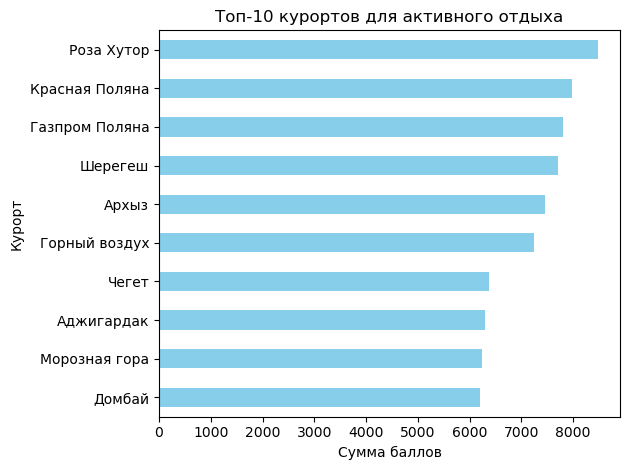

In [102]:
top_10_active.plot(x='name_ru', y='total_score', kind='barh', color='skyblue', legend=False)


plt.title('Топ-10 курортов для активного отдыха')
plt.xlabel('Сумма баллов')
plt.ylabel('Курорт')
plt.tight_layout() 
plt.show()

In [103]:
top_10_relax = relax_rating_df.nlargest(10, 'total_score').sort_values('total_score', ascending=True)

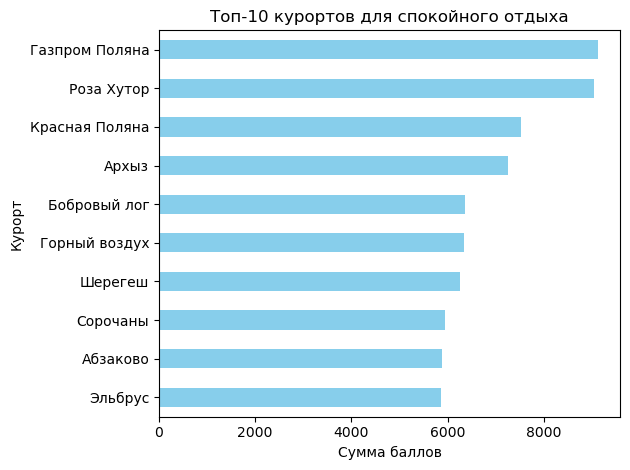

In [105]:
top_10_relax.plot(x='name_ru', y='total_score', kind='barh', color='skyblue', legend=False)


plt.title('Топ-10 курортов для спокойного отдыха')
plt.xlabel('Сумма баллов')
plt.ylabel('Курорт')
plt.tight_layout() 
plt.show()

Наиболее подходящими курортами для любого типа отдыха являются курорты Сочи: Роза Хутор, Красная Поляна и Газпром. Также, на Кавказе есть курорты Архыз, который подойдет туристам с разными потребностями. Любителям экстремального отдыха стоит обратить внимание на Чегет и Домбай, а тем, кто ценит комфорт - Эльбрус.
В рейтинге для активного отдыха после тройки лидеров идёт Шерегеш. Он подходит и тем, кто предпочитает более спокойный отдых. Но нужно учитывать, что курорт отличается более холодным климатом и менее развитой инфстраструктурой.
Для спокойного отдыха можно рассмотреть Бобровый Лог, Горный Воздух, Абзаково и подмосковный курорт Сорочаны. Экстремалам тоже подойдёт Горный Воздух. Также, им стоит обратить внимание на Ажигардак и Морозную Гору.

**Что сделать дальше**

1. Для реального проекта стоит проверить информацию о трассах и подъемниках. Я бы советовала в начале сезона запрашивать её напрямую у курортов. Так как курорты расположены рядом, то данные OSM могут быть некоррктными.

2. Для рейтинга по активному отдыху можно добавить информацию о лавинной опасности. Я начала, но не успела:(

3. Можно сделать больше сценариев: приехал учиться кататься, отдых с детьми, экономный отдых, лучшие ресторнаы и т.д.

4. Было бы классно сделать это на основе ML модели классификации. Но сейчас мало данных для её обучения. Чтобы расширить выборку, можно собрать данные о соразмерных курортах из других стран. В обучающей выборке эксперты должны проставить свои оценки.

**Датафреймы для дашборда**



In [90]:
comparison_df.to_csv(
      'comparison_df.csv', index=False, sep=';', decimal=',', encoding='utf-8-sig'
  )

relax_rating_df.to_csv(
      'relax_rating_df.csv', index=False, sep=';', decimal=',', encoding='utf-8-sig'
  )

active_rating_df.to_csv(
      'active_rating_df.csv', index=False, sep=';', decimal=',', encoding='utf-8-sig'
  )

full_score_df.to_csv(
      'full_score_df.csv', index=False, sep=';', decimal=',', encoding='utf-8-sig'
  )